<a href="https://colab.research.google.com/github/EvanBok/Ashbourne-Data/blob/main/BTA522_final_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Goal and why**

Ashbourne is a multi-store apparel retailer. The goal of this project is to identify which stores, products, customers, and marketing campaigns drive profit for Ashbourne, so that leadership can put its budget and inventory where they earn the most. I chose this dataset because it resembles a real-world analysis and retail analytics is an industry that interests me. Additionally, it has multiple tables and enough detail for me to practice data joining and perform meaningful analysis.

Here are the 3 questions I will aim to answer:
1. Do orders tied to marketing campaigns bring in more sales or profit than orders without a campaign, and which channels (such as TikTok, Instagram, Email, or Print) perform best relative to their budget?
2. Which stores and product categories generate the most profit, and do discounts reduce it?
3. Which customer segments, such as loyalty tier or income bracket, spend the most and are most profitable?

My target audience is Ashbourne’s consumer insights and marketing leadership, such as a VP of retail or marketing director. They decide where to spend ad dollars, which products to stock, and which customers to reward, and they would use these findings to cut waste and increase profit.

**2. Data Description and Codebook**

The Ashbourne dataset has retail data across 6 tables: orders, customers, products, stores, marketing campaigns, and inventory. It also has  about 26,500 orders, 3,000 customers, 16 stores, 34 campaigns.

[View Ashbourne Retail Codebook](https://docs.google.com/spreadsheets/d/1BvgAytO06oSEUaRpibcKSsHm103BOZxu/edit?gid=1943530874#gid=1943530874)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

**3. Set up and document a Python project and directory structure for the analysis**

**Project structure**: The analysis is a single notebook (BTA522_final_project.ipynb). The six source files are stored in a public GitHub repository (EvanBok/Ashbourne-Data, main branch) and read directly from their raw URLs, so the notebook runs from top to bottom without any local files. The tables link through ID columns: orders connects to customers (customer_id), products (product_id), stores (store_id) and campaigns (campaign_id), and inventory connects to products and stores.

In [ ]:
path = "https://raw.githubusercontent.com/EvanBok/Ashbourne-Data/main/"

stores     = pd.read_csv(path + "Ashbourne_Stores.csv")
products   = pd.read_csv(path + "Ashbourne_Products.csv")
orders     = pd.read_csv(path + "Ashbourne_Orders.csv")
campaigns  = pd.read_csv(path + "Ashbourne_Marketing_Campaigns.csv")
inventory  = pd.read_csv(path + "Ashbourne_Inventory.csv")
customers  = pd.read_csv(path + "Ashbourne_Customers.csv")

display(stores.head())
display(products.head())
display(orders.head())
display(campaigns.head())
display(inventory.head())
display(customers.head())

,store_id,store_name,city,store_type,square_footage,open_date
0,1,Ashbourne Fifth Avenue,New York,Flagship,8500,2018-04-12
1,2,Ashbourne SoHo,New York,Boutique,3200,2019-08-21
2,3,Ashbourne Chicago,Chicago,Flagship,7100,2019-11-05
3,4,Ashbourne Boston,Boston,Boutique,2800,2020-02-14
4,5,Ashbourne Woodbury Common,Central Valley,Outlet,5500,2020-09-30


,product_id,product_name,category,sub_category,season,material,unit_cost,retail_price
0,1,Heritage Silk Blend Footwear - Men,Men,Footwear,Spring/Summer,Silk Blend,242.72,896.53
1,2,Heritage Cashmere Shirting - Men,Men,Shirting,Autumn/Winter,Cashmere,126.76,353.12
2,3,Heritage Denim Denim - Men,Men,Denim,Core/All-Season,Denim,284.02,710.49
3,4,Heritage Organic Cotton Shirting - Men,Men,Shirting,Autumn/Winter,Organic Cotton,41.84,106.53
4,5,Heritage Denim Shirting - Women,Women,Shirting,Spring/Summer,Denim,293.18,869.44


,order_id,customer_id,product_id,store_id,campaign_id,order_date,quantity,discount_pct,gross_sales,discount_amount,net_sales,cogs,profit,return_status,rating,delivery_date
0,1,274,6,5,NaN,2023-01-01,1,0.49,193.48,94.81,98.67,52.08,46.59,Completed,5,NaN
1,2,2253,43,6,NaN,2023-01-01,1,0.00,496.59,0.00,496.59,131.02,365.57,Completed,5,NaN
2,3,545,34,2,NaN,2023-01-01,3,0.00,906.84,0.00,906.84,208.50,698.34,Completed,3,NaN
3,4,736,57,2,NaN,2023-01-01,2,0.25,308.12,77.03,231.09,120.80,110.29,Returned,2,NaN
4,5,1132,62,3,NaN,2023-01-01,1,0.00,797.51,0.00,797.51,249.80,547.71,Completed,4,NaN


,campaign_id,campaign_name,channel,budget,start_date,end_date
0,1,Campaign 2023 - Spring Launch,TikTok,20505.57,2023-01-01,2023-02-01
1,2,Campaign 2023 - Spring Launch,Email,18907.44,2023-01-31,2023-03-01
2,3,Campaign 2023 - Autumn Launch,Instagram,14332.01,2023-03-02,2023-04-05
3,4,Campaign 2023 - Holiday Launch,TikTok,23406.22,2023-04-01,2023-04-20
4,5,Campaign 2023 - Spring Push,TikTok,13797.62,2023-05-01,2023-06-07


,inventory_id,product_id,store_id,stock_level,last_restock_date
0,1,1,1,129,2025-11-30
1,2,2,1,113,2025-11-11
2,3,3,1,85,2025-11-29
3,4,4,1,34,2025-11-14
4,5,5,1,58,2025-11-26


,customer_id,gender,age,income_bracket,acquisition_source,city,join_date,loyalty_tier
0,1,Male,27,High,In-Store Walk-in,Los Angeles,2024-06-21,Gold
1,2,Female,56,Low,Organic Search,Miami,2022-10-01,Silver
2,3,Female,44,Ultra-High,Referral,Dallas,2024-05-05,Platinum
3,4,Female,50,Medium,Organic Search,Miami,2024-10-14,Silver
4,5,Male,30,Medium,Social Media,Miami,2022-06-22,Silver


**4. Read the data into Python: Describe the conceptual data type of each variable of interest**



In [ ]:
#Created independent copies of the original dataframes to describe the conceptual data type of each variable of interest
stores_voi = stores[['store_name', 'store_id', 'city', 'store_type']].copy()

products_voi = products[['product_id', 'product_name', 'category', 'unit_cost', 'retail_price', 'sub_category']].copy()

campaigns_voi = campaigns[['campaign_id', 'channel', 'budget']].copy()

orders_voi = orders[['order_id', 'customer_id', 'store_id', 'product_id', 'profit', 'net_sales', 'gross_sales', 'campaign_id', 'order_date', 'return_status', 'discount_pct', 'discount_amount']].copy()

customers_voi = customers[['customer_id', 'income_bracket', 'loyalty_tier', 'join_date', 'gender', 'age']].copy()

In [ ]:
#Describe the conceptual data type of each variable of interest
conceptual_types = {
    "stores_voi": {"store_name":"nominal","store_id":"nominal","city":"nominal","store_type":"nominal"},
    "products_voi": {"product_id":"nominal","product_name":"nominal","category":"nominal","unit_cost":"ratio","retail_price":"ratio","sub_category":"nominal"},
    "campaigns_voi": {"campaign_id":"nominal","channel":"nominal","budget":"ratio"},
    "orders_voi": {"order_id":"nominal","customer_id":"nominal","store_id":"nominal","product_id":"nominal","profit":"ratio","net_sales":"ratio","gross_sales":"ratio","campaign_id":"nominal","order_date":"interval","return_status":"nominal","discount_pct":"ratio","discount_amount":"ratio"},
    "customers_voi": {"customer_id":"nominal","income_bracket":"ordinal","loyalty_tier":"ordinal","join_date":"interval","gender":"nominal","age":"ratio"},
}

voi_datasets = {
    "stores_voi": stores_voi,
    "products_voi": products_voi,
    "campaigns_voi": campaigns_voi,
    "orders_voi": orders_voi,
    "customers_voi": customers_voi
}

summaries = []

#for loop
for name, d in voi_datasets.items():
  summary=pd.DataFrame({
      "conceptual_type": pd.Series(conceptual_types[name]),
      "storage_type": d.dtypes,
      "values": d.count(),
      "missing": d.isna().sum()
  })

  summaries.append(pd.concat({name: summary}))

voi_summary = pd.concat(summaries)

print(voi_summary)

#Campaign_id's that are N/A just mean there was no marketing campaign associated with that order.
#Pandas recognizes them as missing values but they are not a data quality issue.


                              conceptual_type storage_type  values  missing
stores_voi    store_name              nominal       object      16        0
              store_id                nominal        int64      16        0
              city                    nominal       object      16        0
              store_type              nominal       object      16        0
products_voi  product_id              nominal        int64      64        0
              product_name            nominal       object      64        0
              category                nominal       object      64        0
              unit_cost                 ratio      float64      64        0
              retail_price              ratio      float64      64        0
              sub_category            nominal       object      64        0
campaigns_voi campaign_id             nominal        int64      34        0
              channel                 nominal       object      34        0
            

**5. Do any needed data cleaning such as making categorical responses consistent for a variable, not
M, m, Male, and Man for responses to the male gender. Verify that each categorical variable in
your analysis has "clean" data, such as with a bar chart.**

In [ ]:
#Convert "order_date" from object to date.
#This will allow python to recognize it as a date instead of string so I can do date math a date-based grouping.
orders_voi["order_date"] = orders_voi["order_date"].astype("datetime64[ns]")
print(orders_voi["order_date"].dtypes)

customers_voi["join_date"] = customers_voi["join_date"].astype("datetime64[ns]")
print(customers_voi["join_date"].dtypes)

datetime64[ns]
datetime64[ns]


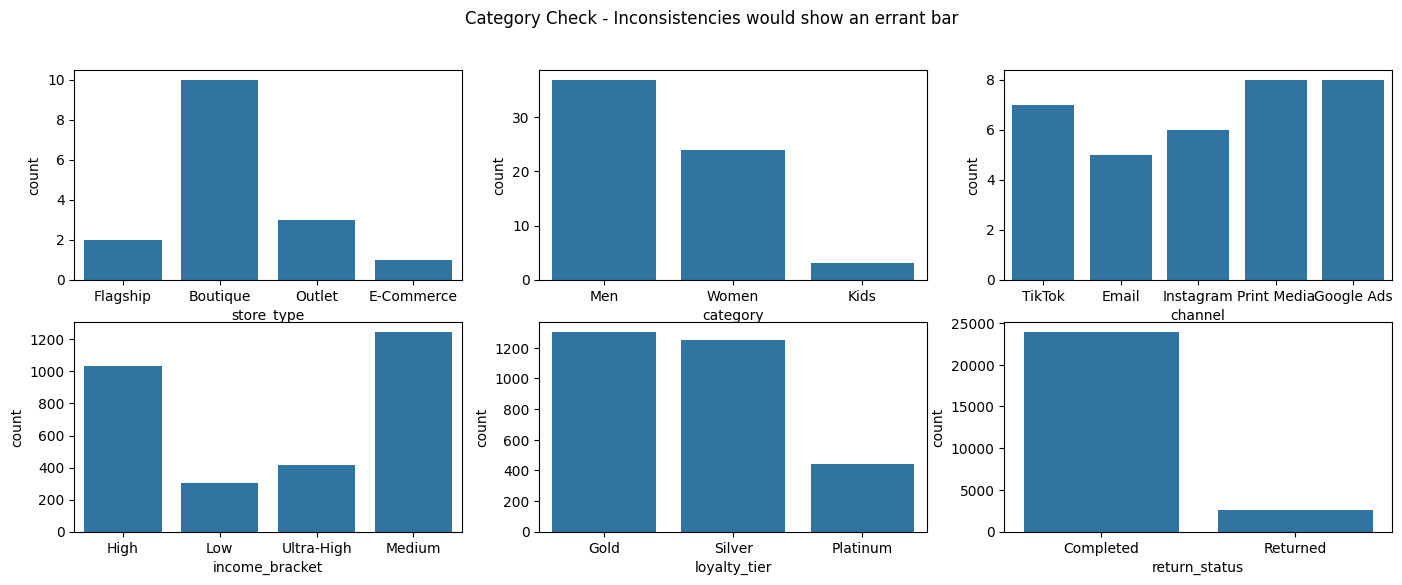

In [ ]:
#Verify that each categorical variable in your analysis has "clean" data, such as with a bar chart
#Each categorical variable shows only its expected categories, with no extra bars from misspellings or capitalization differences.
#The data was already consistent, so no recoding was needed.

#category check graph:Inconsistent spelling would show an extra bar
fig,axes=plt.subplots(2,3, figsize=(17,6))
sns.countplot(data=stores_voi, x="store_type", ax=axes[0,0])
sns.countplot(data=products_voi, x="category", ax=axes[0,1])
sns.countplot(data=campaigns_voi, x="channel", ax=axes[0,2])
sns.countplot(data=customers_voi, x="income_bracket", ax=axes[1,0])
sns.countplot(data=customers_voi, x="loyalty_tier", ax=axes[1,1])
sns.countplot(data=orders, x="return_status", ax=axes[1,2])
plt.suptitle("Category Check - Inconsistencies would show an errant bar")

plt.show()

**6: Convert all categorical variables of interest, integer or character value, type category (Pandas).**

In [ ]:
#converting objects and ID columns to categories to support grouping and filtering

#campaign_id has missing values, so make it a nullable integer first so the categories stay whole numbers.
orders_voi["campaign_id"] = orders_voi["campaign_id"].astype("Int64").astype("category")

orders_voi = orders_voi.astype({
    "customer_id":"category", "store_id": "category", "product_id": "category", "return_status": "category"})

customers_voi = customers_voi.astype({
    "customer_id":"category", "income_bracket": "category", "loyalty_tier": "category", "gender":"category"})

campaigns_voi = campaigns_voi.astype({
    "campaign_id": "category", "channel": "category"})

stores_voi = stores_voi.astype({
    "store_id": "category", "store_name": "category", "city": "category", "store_type": "category"})

products_voi = products_voi.astype({
    "product_id": "category", "product_name": "category",
    "category": "category", "sub_category": "category"})

#ranked variables get a real order. This converts the variable to categorical ordinal rather than nominal because rank order has meaning.
customers_voi["income_bracket"] = customers_voi["income_bracket"].cat.set_categories(
    ["Low", "Medium", "High", "Ultra-High"], ordered=True)
customers_voi["loyalty_tier"] = customers_voi["loyalty_tier"].cat.set_categories(
    ["Silver", "Gold", "Platinum"], ordered=True)

#.update() updates the previously created voi_datasets dictionary
voi_datasets.update({
    "stores_voi": stores_voi,
    "products_voi": products_voi,
    "campaigns_voi": campaigns_voi,
    "orders_voi": orders_voi,
    "customers_voi": customers_voi
})

In [ ]:
#Updated data types for each DataFrame
display(stores_voi[["store_name", "store_id", "city", "store_type"]].dtypes)
display(products_voi[["product_id", "product_name", "category", "sub_category"]].dtypes)
display(campaigns_voi[["campaign_id", "channel"]].dtypes)
display(orders_voi[["customer_id", "store_id", "campaign_id", "product_id", "return_status"]].dtypes)
display(customers_voi[["customer_id", "income_bracket", "loyalty_tier", "gender"]].dtypes)

,0
store_name,category
store_id,category
city,category
store_type,category


,0
product_id,category
product_name,category
category,category
sub_category,category


,0
campaign_id,category
channel,category


,0
customer_id,category
store_id,category
campaign_id,category
product_id,category
return_status,category


,0
customer_id,category
income_bracket,category
loyalty_tier,category
gender,category


**7. Do some other variable transformations, even if just changing units for continuous variables or re- coding the levels of categorical variables.**

In [ ]:
#Net profit margin
orders_voi["profit_margin"] = (
    orders_voi["profit"]/orders_voi["net_sales"]
    ) * 100
orders_voi["profit_margin"] = round(orders_voi["profit_margin"],2)
orders_voi["net_sales"] = round(orders_voi["net_sales"],2)
print(orders_voi[["order_id", "profit_margin"]].head())

   order_id  profit_margin
0         1          47.22
1         2          73.62
2         3          77.01
3         4          47.73
4         5          68.68


In [ ]:
#Assigning categorical variable to campaign or no campaign
orders_voi["campaign_status"] = np.where(
    orders_voi["campaign_id"].notna(),
    "Campaign",
    "No Campaign"
)

orders_voi["campaign_status"] = orders_voi["campaign_status"].astype("category")

print(orders_voi[["campaign_id", "campaign_status"]].head())

  campaign_id campaign_status
0         NaN     No Campaign
1         NaN     No Campaign
2         NaN     No Campaign
3         NaN     No Campaign
4         NaN     No Campaign


In [ ]:
#Extracting year and month from order_date column.
#Yes, I could use Boolean indexing to extract or filter specific year, month, or date from order_date, but creating separate year and month columns is more convenient and organized.
orders_voi["order_year"] = orders_voi["order_date"].dt.year
orders_voi["order_month"] = orders_voi["order_date"].dt.month

print(orders_voi[["order_date", "order_year", "order_month"]].head())


  order_date  order_year  order_month
0 2023-01-01        2023            1
1 2023-01-01        2023            1
2 2023-01-01        2023            1
3 2023-01-01        2023            1
4 2023-01-01        2023            1


**8. Subset the full data set to just variables of interest.**

***Note:*** I initially subsetted the six original datasets earlier in number 4 to focus on variables relevant to my research questions. This allowed me to perform data cleaning and transformations on only the variables I intended to analyze. Here is the verified subset of data.



In [ ]:
for name, d in voi_datasets.items():
  print(d.columns.tolist())
  print()

['store_name', 'store_id', 'city', 'store_type']

['product_id', 'product_name', 'category', 'unit_cost', 'retail_price', 'sub_category']

['campaign_id', 'channel', 'budget']

['order_id', 'customer_id', 'store_id', 'product_id', 'profit', 'net_sales', 'gross_sales', 'campaign_id', 'order_date', 'return_status', 'discount_pct', 'discount_amount', 'profit_margin', 'campaign_status', 'order_year', 'order_month']

['customer_id', 'income_bracket', 'loyalty_tier', 'join_date', 'gender', 'age']



**9. Write the cleaned data to a feather file into the data folder for reading back into Pandas for the actual data analysis.**

In [ ]:
import os
os.makedirs("data", exist_ok=True)

stores_voi.to_feather("data/stores_voi.feather")
products_voi.to_feather("data/products_voi.feather")
campaigns_voi.to_feather("data/campaigns_voi.feather")
orders_voi.to_feather("data/orders_voi.feather")
customers_voi.to_feather("data/customers_voi.feather")


stores_clean = pd.read_feather("data/stores_voi.feather")
products_clean = pd.read_feather("data/products_voi.feather")
campaigns_clean = pd.read_feather("data/campaigns_voi.feather")
orders_clean = pd.read_feather("data/orders_voi.feather")
customers_clean = pd.read_feather("data/customers_voi.feather")

campaigns_clean.head()

,campaign_id,channel,budget
0,1,TikTok,20505.57
1,2,Email,18907.44
2,3,Instagram,14332.01
3,4,TikTok,23406.22
4,5,TikTok,13797.62


**10. For merging, either read two different data sets into Pandas data frames with a common variable and merge. Or, artificially create two data sets by doing a subsetting by moving some variables into one new data frame and the remaining variables into the other newly created data frame. Then merge back into a single data frame as if the data had arrived in separate files. Following
that procedure provides examples of both subsetting and merging data frames.**

In [ ]:
#Connected two tables on the common variable: "store_id"
pd.merge(orders_clean, stores_clean, on = "store_id", how="inner").head()

,order_id,customer_id,store_id,product_id,profit,net_sales,gross_sales,campaign_id,order_date,return_status,discount_pct,discount_amount,profit_margin,campaign_status,order_year,order_month,store_name,city,store_type
0,1,274,5,6,46.59,98.67,193.48,NaN,2023-01-01,Completed,0.49,94.81,47.22,No Campaign,2023,1,Ashbourne Woodbury Common,Central Valley,Outlet
1,2,2253,6,43,365.57,496.59,496.59,NaN,2023-01-01,Completed,0.00,0.00,73.62,No Campaign,2023,1,Ashbourne Dallas,Dallas,Boutique
2,3,545,2,34,698.34,906.84,906.84,NaN,2023-01-01,Completed,0.00,0.00,77.01,No Campaign,2023,1,Ashbourne SoHo,New York,Boutique
3,4,736,2,57,110.29,231.09,308.12,NaN,2023-01-01,Returned,0.25,77.03,47.73,No Campaign,2023,1,Ashbourne SoHo,New York,Boutique
4,5,1132,3,62,547.71,797.51,797.51,NaN,2023-01-01,Completed,0.00,0.00,68.68,No Campaign,2023,1,Ashbourne Chicago,Chicago,Flagship


In [ ]:
#Created one merged table using five cleaned datasets with variables of interest, connected on primary and foreign keys
merged_df = (
    orders_clean
    .merge(stores_clean, on="store_id", how="left")
    .merge(products_clean, on="product_id", how = "left")
    .merge(campaigns_clean, on ="campaign_id", how="left")
    .merge(customers_clean, on="customer_id", how="left")
)

display(merged_df.head())
print(merged_df.shape)

,order_id,customer_id,store_id,product_id,profit,net_sales,gross_sales,campaign_id,order_date,return_status,...,unit_cost,retail_price,sub_category,channel,budget,income_bracket,loyalty_tier,join_date,gender,age
0,1,274,5,6,46.59,98.67,193.48,NaN,2023-01-01,Completed,...,52.08,193.48,Accessories,NaN,NaN,Medium,Silver,2023-06-14,Male,37
1,2,2253,6,43,365.57,496.59,496.59,NaN,2023-01-01,Completed,...,131.02,496.59,Outerwear,NaN,NaN,High,Gold,2023-11-18,Female,25
2,3,545,2,34,698.34,906.84,906.84,NaN,2023-01-01,Completed,...,69.50,302.28,Footwear,NaN,NaN,High,Platinum,2022-06-15,Male,19
3,4,736,2,57,110.29,231.09,308.12,NaN,2023-01-01,Returned,...,60.40,154.06,Accessories,NaN,NaN,Ultra-High,Platinum,2023-09-30,Female,31
4,5,1132,3,62,547.71,797.51,797.51,NaN,2023-01-01,Completed,...,249.80,797.51,Accessories,NaN,NaN,High,Platinum,2023-07-30,Female,34


(26500, 31)


**11. Data Analysis I: Display a bar chart or histogram for at least several variables of interest, and comment.**

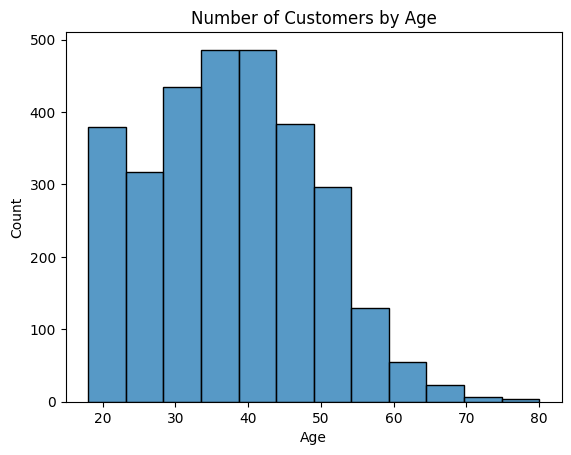

In [ ]:
sns.histplot(data=customers_voi, x="age", binwidth=5)
plt.title("Number of Customers by Age")
plt.xlabel("Age")
plt.show()
#Customer ages range from 18 to 80, with most customers in their 30s and 40s.
#The distribution is skewed right, with relatively few customers over 55.

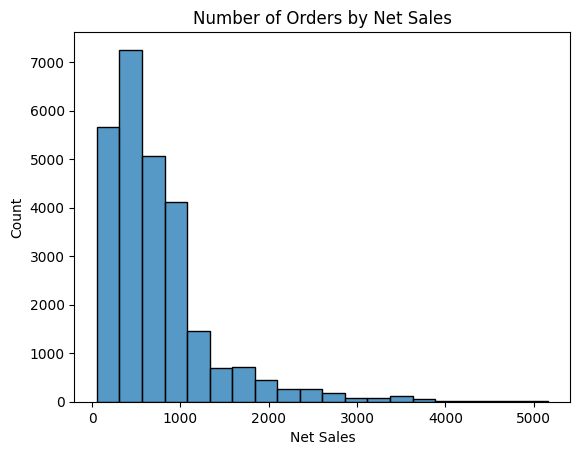

In [ ]:
sns.histplot(data=merged_df, x="net_sales", binwidth=250)
plt.title("Number of Orders by Net Sales")
plt.xlabel("Net Sales")
plt.show()
#Order net sales range from about $50 to $5,200, with most orders under $1,000.
#The distribution is skewed right, with only a small number of orders above $2,000.

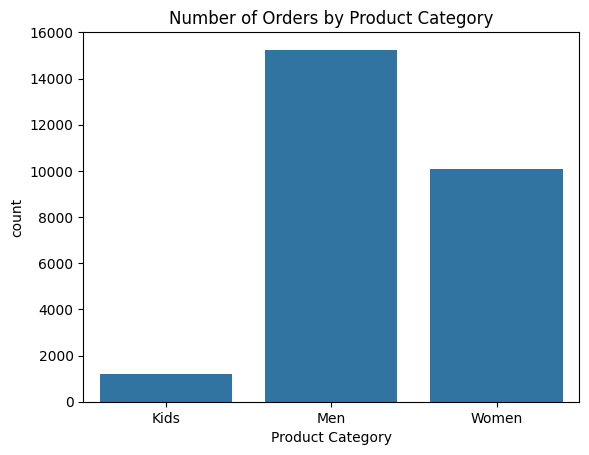

In [ ]:
sns.countplot(data=merged_df, x="category")
plt.title("Number of Orders by Product Category")
plt.xlabel("Product Category")
plt.show()
#Men's products account for the most orders and Kids account for the fewest by a large margin.

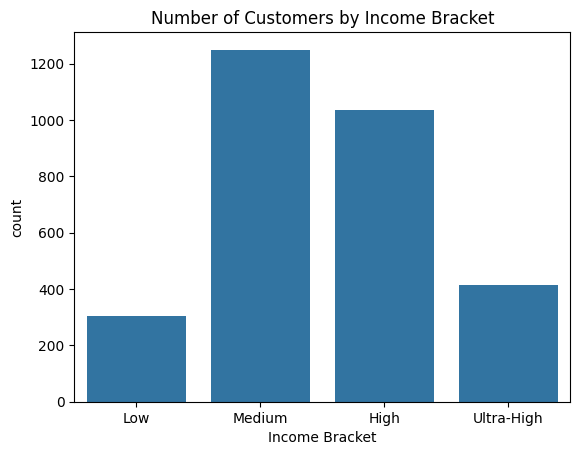

In [ ]:
sns.countplot(data=customers_voi, x="income_bracket")
plt.title("Number of Customers by Income Bracket")
plt.xlabel("Income Bracket")
plt.show()
#Customers in the Medium Income Bracket make up the largest amount of Ashbourne's customer base and the Low Income Bracket makes up the least.

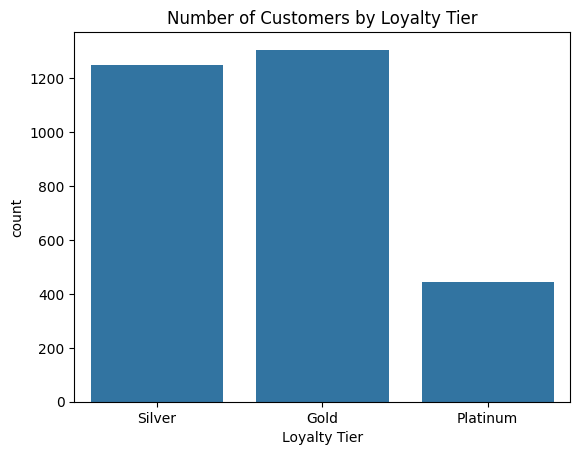

In [ ]:
sns.countplot(data=customers_voi, x="loyalty_tier")
plt.title("Number of Customers by Loyalty Tier")
plt.xlabel("Loyalty Tier")
plt.show()
#Gold tier has the most customers and Platinum is the smallest tier by a wide margin.

**12: Data Analysis II: Do a data aggregation and interpret.**

**Question 1 to guide analysis: Do orders tied to marketing campaigns bring in more sales or profit than orders without a campaign, and which channels (such as TikTok, Instagram, Email, or Print) perform best relative to their budget?**

                 count    net_sales      profit  avg_net_sales  avg_profit
campaign_status                                                           
Campaign          8092   5968134.66  4075418.21         737.54      503.64
No Campaign      18408  13556190.29  9262583.95         736.43      503.18


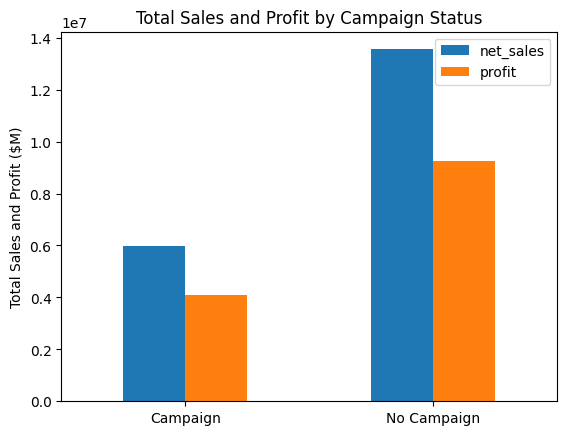

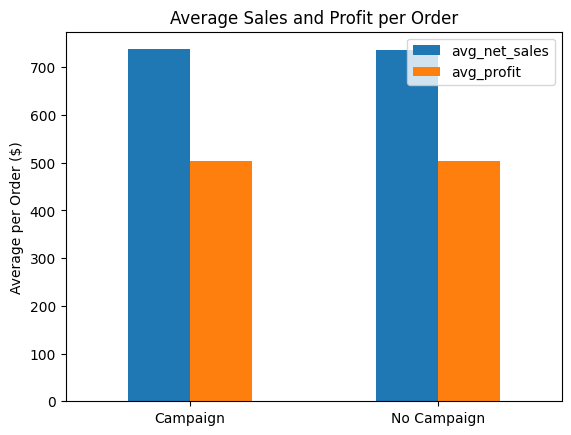

In [ ]:
#Do marketing campaigns lead to more sales and profit?

campaign_summary = merged_df.groupby(
    "campaign_status", observed=True
).agg(
    count=("order_id", "count"),
    net_sales=("net_sales", "sum"),
    profit=("profit", "sum"),
    avg_net_sales=("net_sales", "mean"),
    avg_profit=("profit", "mean")
).round(2)
print(campaign_summary)

#Total Sales and Profit by Campaign Status
campaign_summary[["net_sales", "profit"]].plot.bar(rot=0)
plt.xlabel("")
plt.ylabel("Total Sales and Profit ($M)")
plt.title("Total Sales and Profit by Campaign Status")
plt.show()
#The main caveat is that there are a lot more orders with no campaign than with a campaign (18,408 vs 8092), so I compare the average profit for each instead.

#Average Sales and Profit per Order
campaign_summary[["avg_net_sales", "avg_profit"]].plot.bar(rot=0)
plt.title("Average Sales and Profit per Order")
plt.xlabel("")
plt.ylabel("Average per Order ($)")
plt.show()
#No-campaign orders have higher totals only because there are more of them (18,408 vs. 8,092).
#Per order, the two groups are nearly identical in sales and profit, so campaign orders do not bring in more sales or profit.

#Findings:
#Orders tied to marketing campaigns bring in about the same sales and profit per order as orders without a campaign, so campaigns do not make individual orders more valuable.

,net_sales,profit,budget,sales_per_budget_dollar,profit_per_budget_dollar
channel,,,,,
Google Ads,1429155.24,979202.34,177821.82,8.04,5.51
Instagram,1068714.54,732091.80,139533.26,7.66,5.25
TikTok,1207366.82,821754.02,173640.07,6.95,4.73
Email,881088.93,599325.16,130086.30,6.77,4.61
Print Media,1381809.13,943044.89,238146.45,5.80,3.96


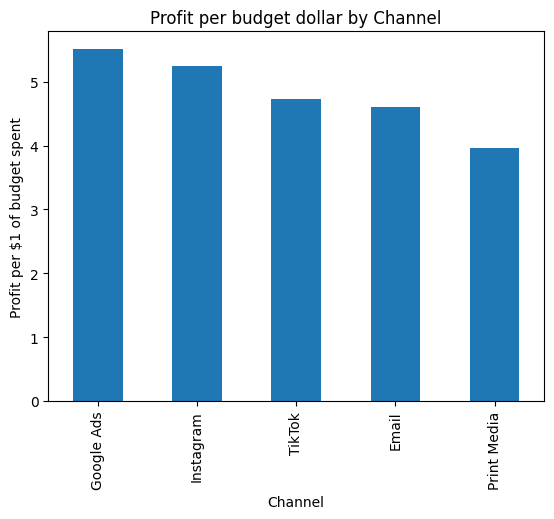

In [ ]:
#Net sales and profit per channel
channel_summary=merged_df.groupby("channel", observed=True)[["net_sales", "profit"]].sum()

#I pull budget from campaigns_voi because merged_df has one row per order so each campaigns budget is repeated on every order that has a campaign
channel_summary["budget"] = campaigns_voi.groupby("channel", observed=True)["budget"].sum()

#How much sales and profit each budget dollar brings in
channel_summary["sales_per_budget_dollar"] = (channel_summary["net_sales"] / channel_summary["budget"]).round(2)
channel_summary["profit_per_budget_dollar"] = (channel_summary["profit"] / channel_summary["budget"]).round(2)

channel_summary = channel_summary.sort_values("sales_per_budget_dollar", ascending=False)
channel_summary = channel_summary.sort_values("profit_per_budget_dollar", ascending=False)
display(channel_summary)

#Graph
channel_summary["profit_per_budget_dollar"].plot.bar()
plt.title("Profit per budget dollar by Channel")
plt.ylabel("Profit per $1 of budget spent")
plt.xlabel("Channel")
plt.show()

#Findings:
#Relative to budget, Google Ads returns the most profit per dollar spent and Print Media the least.


**Question 2 to guide analysis: Which stores and product categories generate the most profit, and do discounts reduce it?**

,orders,total_profit,avg_profit,total_sales,avg_sales
category,,,,,
Men,15248,7782393.19,510.39,11407944.75,748.16
Women,10062,4668612.29,463.98,6878549.49,683.62
Kids,1190,886996.68,745.38,1237830.71,1040.19


Text(0, 0.5, 'Total Profit($M)')

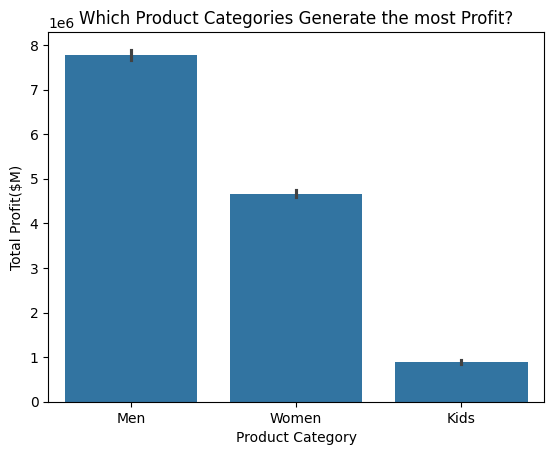

In [ ]:
#Which product categories generate the most profit?
category_profit = merged_df.groupby("category", observed=True).agg(
    orders=("order_id", "count"),
    total_profit=("profit","sum"),
    avg_profit=("profit","mean"),
    total_sales=("net_sales", "sum"),
    avg_sales=("net_sales", "mean")

).round(2).sort_values("total_profit", ascending=False)
display(category_profit)

sns.barplot(
    data=merged_df,
    x="category",
    y="profit",
    estimator="sum",
    order=category_profit.index.tolist()
    )
plt.title("Which Product Categories Generate the most Profit?")
plt.xlabel("Product Category")
plt.ylabel("Total Profit($M)")

#Findings:
#Men generates the most total profit (~$7.8M), then Women (~$4.7M) and Kids (~$890K).
#Kids has the fewest orders (1,190), but its average profit per order is the highest (~$745 vs. ~$510 for Men and ~$464 for Women), mainly because its average amount spent per order is larger (~$1,040 vs. ~$748 for Men).
#So Kids is the most valuable per order, but its small number of orders keeps its total profit the lowest.

,stores,orders,total_profit,avg_profit,total_sales,avg_sales,profit_per_store
store_type,,,,,,,
E-Commerce,1,9329,5076272.63,544.138989,7258470.47,778.054504,5076273.0
Boutique,10,7711,4197267.06,544.322015,5992434.34,777.128043,419727.0
Flagship,2,4684,2609170.23,557.038905,3727070.91,795.702585,1304585.0
Outlet,3,4776,1455292.24,304.709430,2546349.23,533.155199,485097.0


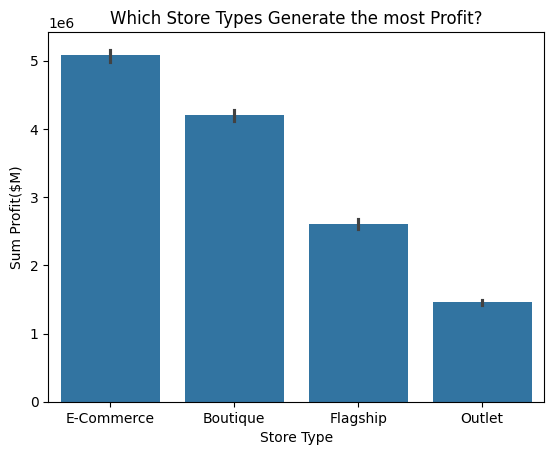

In [ ]:
#Which store type generates the most profit?
store_type_profit=(merged_df.groupby("store_type", observed=True).agg(
  stores=("store_id", "nunique"),
  orders=("order_id", "count"),
  total_profit=("profit", "sum"),
  avg_profit=("profit", "mean"),
  total_sales=("net_sales", "sum"),
  avg_sales=("net_sales", "mean")
  ).sort_values("total_profit", ascending=False)
)
store_type_profit["profit_per_store"]=(store_type_profit["total_profit"] / store_type_profit["stores"]).round(0)
display(store_type_profit)
sns.barplot(
    data=merged_df,
    x="store_type",
    y="profit",
    estimator="sum",
    order=store_type_profit.index.tolist())
plt.title("Which Store Types Generate the most Profit?")
plt.xlabel("Store Type")
plt.ylabel("Sum Profit($M)")
plt.show()

#Findings:
#E-Commerce generates the most total profit (~$5.1M), followed by Boutique (~$4.2M), Flagship (~$2.6M) and Outlet (~$1.5M).
#Outlet's orders are worth less (avg profit ~$305 vs. ~$545 to ~$557 for the others), so it ranks last despite having as many orders as Flagship.
#Boutique ranks second because it has 10 stores. Per store, E-Commerce (~$5.1M, 1 online store) and Flagship (~$1.3M per store, 2 stores) are strongest, and Boutique is lowest (~$420K, 10 stores).

,orders,avg_margin,avg_profit
discount_pct,,,
0.00,16313,70.0,577.3
0.05,116,68.0,608.3
0.06,259,68.0,551.8
0.07,270,67.8,552.2
0.08,266,67.0,515.4


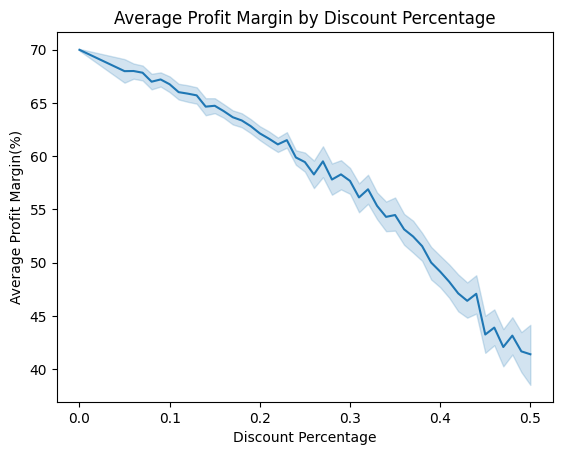

In [ ]:
#Average Profit Margin by Discount Percentage
discount_summary = merged_df.groupby("discount_pct").agg(
    orders=("order_id", "count"),
    avg_margin=("profit_margin", "mean"),
    avg_profit=("profit", "mean"),
).round(1)
display(discount_summary.head())

#Line chart
sns.lineplot(
    data=merged_df,
    x="discount_pct",
    y="profit_margin", )
plt.title("Average Profit Margin by Discount Percentage")
plt.xlabel("Discount Percentage")
plt.ylabel("Average Profit Margin(%)")
plt.show()

#Findings:
#Starting from 70% profit margin with no discount, average profit margin decreases as discount percentage increases (inverse relationship).

**Question 3 to guide analysis: Which customer segments, such as loyalty tier or income bracket, spend the most and are most profitable?**

,customers,total_sales,total_profit,orders,avg_order,orders_per_customer,profit_per_customer,sales_per_customer
loyalty_tier,,,,,,,,
Platinum,444,6851745.7,4680258.9,9195,745.2,20.7,10541.1,15431.9
Gold,1306,6494179.6,4445413.5,8789,738.9,6.7,3403.8,4972.6
Silver,1249,6178399.7,4212329.7,8516,725.5,6.8,3372.6,4946.7


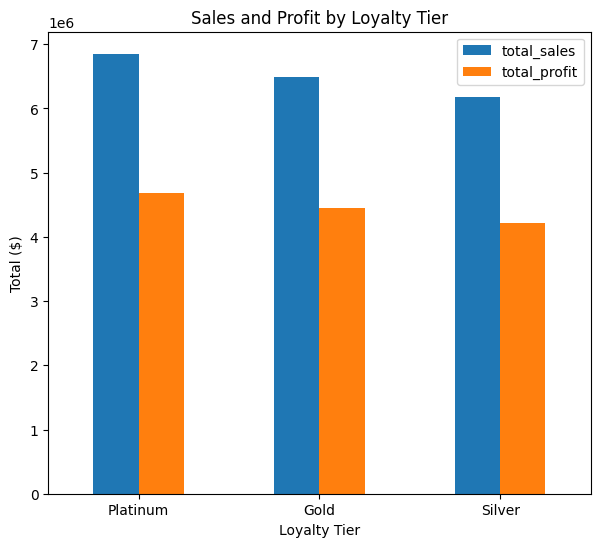

In [ ]:
#Which loyalty tier spends the most and is the most profitable?
loyalty_summary=merged_df.groupby("loyalty_tier", observed=True).agg(
    customers=("customer_id", "nunique"),
    total_sales=("net_sales", "sum"),
    total_profit=("profit", "sum"),
    orders=("order_id", "count"),
    avg_order=("net_sales", "mean")
).round(1).sort_values("total_profit", ascending=False)
loyalty_summary["orders_per_customer"]=(loyalty_summary["orders"] / loyalty_summary["customers"]).round(1)
loyalty_summary["profit_per_customer"]=(loyalty_summary["total_profit"] / loyalty_summary["customers"]).round(1)
loyalty_summary["sales_per_customer"]=(loyalty_summary["total_sales"] / loyalty_summary["customers"]).round(1)
display(loyalty_summary)

#Graph
loyalty_summary[["total_sales", "total_profit"]].plot.bar(rot=0, figsize=(7,6))
plt.title("Sales and Profit by Loyalty Tier")
plt.xlabel("Loyalty Tier")
plt.ylabel("Total ($)")
plt.show()

#Initial findings:
#Platinum spends the most ($6.9M in sales) and is the most profitable ($4.7M), followed by Gold and Silver.
#The tiers are fairly close in total, but Platinum gets there with only 444 customers, compared with about 1,300 for Gold and 1,250 for Silver.
#My hypothesis is that Platinum customers buy more expensive items and/or more orders. To test these, I added orders_per_customer and avg_order to the table.

#Further analysis:
#Platinum customers order more often, with ~21 orders each vs ~7 each for Silver and Gold, but average order size(avg_order:average amount spent on one order) is similar across tiers ranging from $725 to $745.
#So order frequency, not average order size, explains why Platinum customers have the most total sales and profit despite having the least number of customers.
#Platinum customers also generate the most sales per customer (~$15,400) and profit per customer (~$10,500), about three times the ~$5,000 in sales and ~$3,400 in profit for Gold and Silver customers.
#Taken together, Platinum customers are clearly the most valuable in terms of sales volume and profit despite having the least number of customers.

,customers,total_sales,total_profit,orders,avg_order,orders_per_customer,profit_per_customer,sales_per_customer
income_bracket,,,,,,,,
High,1035,8608494.8,5885827.9,11566,744.3,11.2,5686.8,8317.4
Medium,1248,6146971.6,4189585.4,8458,726.8,6.8,3357.0,4925.5
Ultra-High,413,3304612.3,2260561.3,4430,746.0,10.7,5473.5,8001.5
Low,303,1464246.3,1002027.5,2046,715.7,6.8,3307.0,4832.5


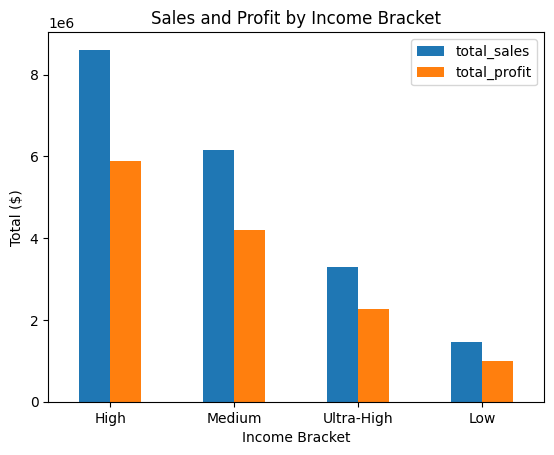

In [ ]:
#Which income bracket spends the most and is most profitable?
bracket_summary = merged_df.groupby("income_bracket", observed=True).agg(
    customers=("customer_id", "nunique"),
    total_sales=("net_sales", "sum"),
    total_profit=("profit", "sum"),
    orders=("order_id", "count"),
    avg_order=("net_sales", "mean"),
).round(1).sort_values("total_profit", ascending=False)
bracket_summary["orders_per_customer"]=(bracket_summary["orders"] / bracket_summary["customers"]).round(1)
bracket_summary["profit_per_customer"]=(bracket_summary["total_profit"] / bracket_summary["customers"]).round(1)
bracket_summary["sales_per_customer"]=(bracket_summary["total_sales"] / bracket_summary["customers"]).round(1)
display(bracket_summary)

#Graph
bracket_summary[["total_sales", "total_profit"]].plot.bar(rot=0)
plt.title("Sales and Profit by Income Bracket")
plt.xlabel("Income Bracket")
plt.ylabel("Total ($)")
plt.show()

#Initial Findings:
#High income customers spend the most($8.6M) and are the most profitable ($5.9M), followed by Medium, Ultra-High, and Low.

#Further Analysis:
#How do we know which customers are most valuable?
#Medium has the most customers (1,248), but High and Ultra-High customers generate the most profit per customer with ~$5,500 to ~$5,700 compared to Low and Medium with ~$3,300 to ~$3,400.
#They also generate the most sales per customer with ~$8000 to ~8,300 compared to ~$4,800 to ~$4,900.
#This could be because they order more often with ~11 orders each vs ~7, since average order size is similar across brackets.
#Although Ultra-High customers make up a small group (413), I would say High and Ultra-High customers are the most valuable because they generate the most profit and sales per customer.


**13. As part of iterative EDA, use Data Analysis I & II insights to fine-tune your original 2-3 questions, and frame 2 questions that are the next steps that you would look into and why they matter. No new coding is expected for these questions**

**Fine-tuned questions**
1. Since campaign orders are worth the same as non-campaign orders, do campaigns add orders, and which channels return the most profit per budget dollar?
    - My analysis shows average profit and sales being similar for campaign and non-campaign orders, so campaigns would only pay off by adding orders. For channels, profit per budget dollar is more meaningful because it show's which individual channels perform best.

2. Which store types and product categories generate the most profit once store count and order volume are accounted for, and do discounts reduce it?
    - I specified store type and product categories as the groups of analysis. I added "once store count and order volume are accounted for" because Boutique stores rank second in profit only because it has 10 stores, while E-commerce and Flagship generate more profit per store.

3. Which customer segments are most worth retaining, based on profit per customer and order frequency rather than totals alone?
    - My analysis shows sales and profit by loyalty tier are very close, with Platinum slightly ahead. Looking into profit, sales, and orders per customer gives better insight beyond totals.

**2 New Questions**
1. Why do Outlet stores earn so much less profit than Flagship stores despite having a similar amount of orders?
    - This matters because it helps identify why Outlet stores generate significantly less than flagship stores despite having similar order volumes. Understanding why could help identify opportunities to improve outlet store profitability through pricing, discount, and product selection.
2. Do profit and marketing campaign results change by month or year?
    - This matters because understanding seasonal patterns in profitability and campaign performance would help determine when to schedule campaigns, allocate marketing budgets, and adjust inventory to meet customer demand.


**14. Generative AI: Use a generative tool (your choice) to fully evaluate the analysis and EDA sections (#11 through #14). The evaluation should be based on all goals/parameters/target audience mentioned in #1.**

**ChatGPT Prompt:**
In my attached Google Colab file, write a paragraph fully evaluating my analysis and EDA sections (#11-#14) based on how well they answer the goals/parameters/target audience mentioned in question #1. Explain and justify your answers.

**AI Output:**
Overall, the analysis and exploratory data analysis (EDA) effectively address the three research questions and the main goal of identifying which stores, products, customers, and marketing campaigns drive profitability for Ashbourne. Section 11 provides a useful foundation by examining customer demographics, order values, product categories, and loyalty tiers, although these initial visualizations are primarily descriptive and do not directly explain profitability. Section 12 is the strongest part of the analysis because it moves beyond total sales and profit to consider differences in order volume, profit per store, marketing budget, and customer purchasing behavior. For example, comparing average profit per order reveals that campaign and non-campaign orders generate nearly identical amounts of profit, while the channel analysis identifies Google Ads as generating the most profit per marketing budget dollar and Print Media the least. The store analysis also shows why total profit alone can be misleading, as Boutique stores generate substantial total profit partly because there are more locations, while Outlet stores generate considerably less profit per order than Flagship stores. Additionally, the customer segmentation analysis identifies Platinum loyalty members and High and Ultra-High income customers as particularly valuable based on profit per customer and purchasing frequency. These findings are relevant to Ashbourne's consumer insights and marketing leadership because they can inform decisions about marketing spending, customer retention, and inventory allocation. Section 13 demonstrates effective iterative EDA by refining the original questions based on these findings and identifying further opportunities to investigate Outlet store profitability and seasonal patterns.

However, the analysis has some limitations. It does not directly examine individual product profitability or use the inventory dataset, limiting its ability to recommend specific inventory decisions. Additionally, comparing campaign-associated orders with non-campaign orders does not establish whether campaigns actually caused additional sales, and the analysis does not account for customer acquisition costs or retention expenses. Some visualizations could also be improved through clearer axis formatting and more consistent units. Overall, the analysis provides meaningful, actionable insights for the intended leadership audience and successfully addresses the main research questions, but further investigation would be needed before making major budget, inventory, or marketing decisions.

**15. Generative AI Follow-Up: Reflect on the feedback from #14. What are your takeaways from the Generative AI feedback? Did you accomplish your goal? Did the feedback bring up anything relevant that you missed? What revisions would you make based on the feedback?**


For the most part, I think AI's analysis of my analysis was relevant.

From the AI response, I accomplished my goal of answering my initial questions and tailoring the analysis towards my Ashbourne's leadership team. My biggest strength was following the process of creating initial descriptive visualization for total sales and profit, then going beyond those using aggregations, different metrics, and further visualizations to uncover things that weren't visible in initial analysis.  

AI recommended several things that I could improve on. The first was doing analysis on Ashbourne's inventory. I think this is a good subject for analysis because inventory is an important factor to consider in budgeting and marketing decisions. I didn't include this in my initial questions, but it would be good to develop questions for further analysis. Second, AI suggested going deeper into my campaign associated orders with non-campaign orders because it doesn't establish whether campaigns actually caused additional sales. This is something I missed, and I agree with this suggestion because it's an actionable metric that leadership would likely want to know, since it's directly tied to making money. The suggestion on visualization axis formatting and consistent units wasn't very specific so it's hard to know which graphs it's recommending, but looking back on my analysis, percentage units could be more consistent.

Overall, AI's analysis was helpful and here are the main revisions I would make based on its feedback.
- Develop questions and include an analysis on Ashbourne's Inventory.
- Do further analysis on campaign associated orders vs non-campaign orders to determine whether campaigns lead to additional sales.
- Make chart axis and units more consistent.



**Generative AI Appendix**: [View PDF document](https://github.com/EvanBok/Ashbourne-Data/blob/main/BTA522%20AI%20Appendex%20(1).pdf)